# Project 3: Advanced Statistics
### Testing Business Claims with Evidence, Not Opinion
**Data Analyst Training Program | Mini Project, 2nd Year Engineering**

**Input:** `retail_customer_sales_cleaned.csv` (cleaned dataset from Project 1).

Claims tested: *"the regions sell differently"*, *"discounts hurt profit"*, *"segments buy different things"*, plus a confidence interval, two regressions and a bonus z-test. All tests use **alpha = 0.05**.

**Libraries:** `pandas`, `numpy`, `scipy.stats`, `matplotlib`, `seaborn`. The regression is written directly with `numpy` and `scipy.stats` (the standard OLS formulas) so that the notebook runs even where `statsmodels` is not installed; the results can be cross-checked with `statsmodels.OLS` if it is available.

## 1. Setup and Descriptive Statistics

In [1]:
import json
import pandas as pd, numpy as np
from scipy import stats
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.options.display.float_format = '{:,.3f}'.format

df = pd.read_csv('retail_customer_sales_cleaned.csv', parse_dates=['Order_Date', 'Delivery_Date'])
ALPHA = 0.05
R = {}     # results store, used by the written report
print('Rows:', len(df))

Rows: 7000


In [2]:
cols = ['Sales', 'Profit', 'Age', 'Income']
d = df[cols]
desc = pd.DataFrame({'mean': d.mean(), 'median': d.median(), 'mode': d.mode().iloc[0], 'variance': d.var(), 'std': d.std(),
                     'P5': d.quantile(.05), 'P25': d.quantile(.25), 'P75': d.quantile(.75), 'P95': d.quantile(.95),
                     'IQR': d.quantile(.75) - d.quantile(.25)})
R['descriptive'] = desc.round(2).to_dict('index')
desc.round(2)

             mean     median       mode        variance        std         P5        P25        P75         P95        IQR
Sales  10,961.600  4,825.560    258.730 211,674,394.520 14,549.030    498.350  1,815.460 14,095.340  41,542.620 12,279.890
Profit  3,589.700  1,528.700     19.470  24,285,381.420  4,928.020    153.660    574.080  4,533.280  13,749.640  3,959.200
Age        36.050     36.000     18.000         108.300     10.410     18.000     29.000     43.000      54.000     14.000
Income 54,816.190 48,846.620 15,000.000 956,507,075.890 30,927.450 23,778.870 37,125.400 65,721.730 102,537.520 28,596.330


## 2. 95% Confidence Interval for Average Sales
For a sample mean, `CI = mean +/- t(0.975, n-1) x s / sqrt(n)`. With n = 7,000 the t and normal values are practically identical.

In [3]:
s = df.Sales; n = len(s); m = s.mean(); se = s.sem()
tcrit = stats.t.ppf(0.975, n - 1)
lo, hi = m - tcrit * se, m + tcrit * se
print(f'n = {n:,} | mean = {m:,.2f} | std = {s.std():,.2f} | standard error = {se:,.2f}')
print(f't critical (df={n-1}) = {tcrit:.4f}')
print(f'95% CI for mean Sales: Rs {lo:,.2f} to Rs {hi:,.2f}')
print('Check with scipy:', tuple(round(x, 2) for x in stats.t.interval(0.95, n - 1, loc=m, scale=se)))

# Sales is strongly skewed, so confirm the interval with a bootstrap (resample 5,000 times)
rng = np.random.default_rng(42)
boot = np.array([rng.choice(s.values, n).mean() for _ in range(5000)])
print('Bootstrap 95%% interval  : Rs %.2f to Rs %.2f' % tuple(np.percentile(boot, [2.5, 97.5])))
R['ci'] = dict(n=n, mean=m, se=se, lo=lo, hi=hi, boot_lo=float(np.percentile(boot, 2.5)), boot_hi=float(np.percentile(boot, 97.5)))

n = 7,000 | mean = 10,961.60 | std = 14,549.03 | standard error = 173.89
t critical (df=6999) = 1.9603
95% CI for mean Sales: Rs 10,620.71 to Rs 11,302.48
Check with scipy: (np.float64(10620.71), np.float64(11302.48))
Bootstrap 95% interval  : Rs 10624.33 to Rs 11306.96


**Plain-language meaning:** the average sale in our 7,000 orders is about Rs 10,960. We are 95% confident that the *true long-run average order value* of this business lies within the interval above. The interval describes the **average**, not individual orders: most single orders are far below that average because a few very large orders pull it up (the bootstrap check agrees, so the skew does not distort the interval).

## 3. Hypothesis Tests
Before testing, look at the group distributions. Sales is right-skewed, so **Welch's t-test** (which does not assume equal variances) is used for two groups, and a rank-based test is reported as a robustness check.

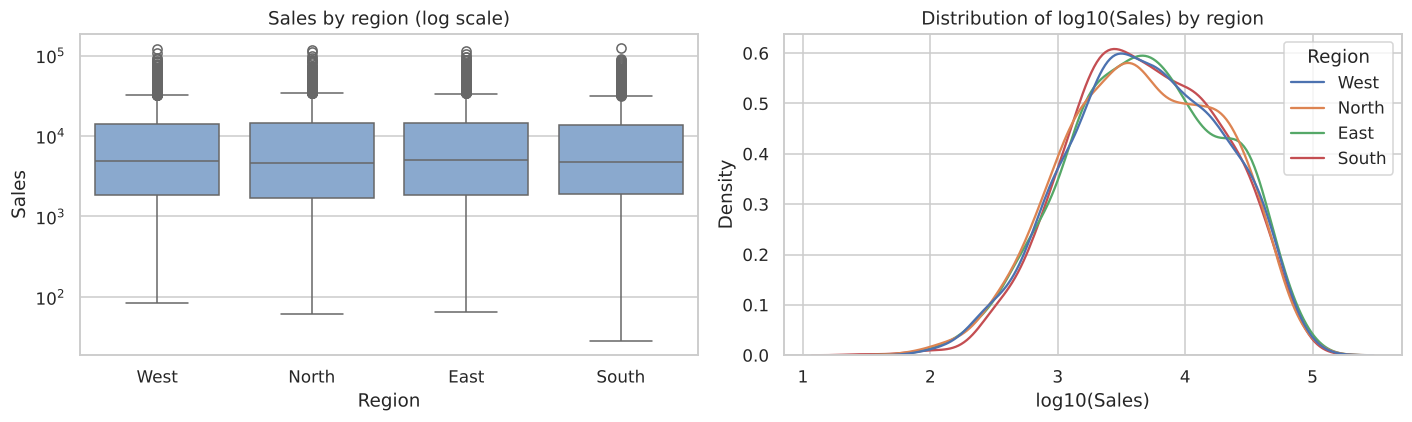

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x='Region', y='Sales', color='#7FA8D9', ax=axes[0]); axes[0].set_yscale('log'); axes[0].set_title('Sales by region (log scale)')
sns.kdeplot(data=df, x=np.log10(df.Sales), hue='Region', common_norm=False, ax=axes[1]); axes[1].set_title('Distribution of log10(Sales) by region'); axes[1].set_xlabel('log10(Sales)')
plt.tight_layout()

### Test 1. t-test: Is average Sales different between North and South?
- **Business question:** Does the North region really sell a different amount per order than the South?
- **H0:** mean Sales (North) = mean Sales (South)
- **H1:** mean Sales (North) != mean Sales (South) (two-sided)
- **Test:** Welch's independent-samples t-test (two independent groups, unequal variances allowed)

In [5]:
north = df.loc[df.Region == 'North', 'Sales']; south = df.loc[df.Region == 'South', 'Sales']
print(f'North: n={len(north)}, mean={north.mean():,.2f}, std={north.std():,.2f}')
print(f'South: n={len(south)}, mean={south.mean():,.2f}, std={south.std():,.2f}')
lev = stats.levene(north, south)
print(f"Levene test for equal variances: p = {lev.pvalue:.4f} -> {'unequal' if lev.pvalue < ALPHA else 'similar'} variances (Welch used either way)")
t = stats.ttest_ind(north, south, equal_var=False)
diff = north.mean() - south.mean()
se_d = np.sqrt(north.var() / len(north) + south.var() / len(south))
d_cohen = diff / np.sqrt((north.var() + south.var()) / 2)
print(f'Difference in means (North - South): Rs {diff:,.2f}  (95% CI Rs {diff-1.96*se_d:,.0f} to Rs {diff+1.96*se_d:,.0f})')
print(f't statistic = {t.statistic:.4f} | p-value = {t.pvalue:.4f} | Cohen d = {d_cohen:.3f}')
mw = stats.mannwhitneyu(north, south, alternative='two-sided'); print(f'Robustness check (Mann-Whitney U): p = {mw.pvalue:.4f}')
print('DECISION:', 'Reject H0' if t.pvalue < ALPHA else 'Fail to reject H0', f'at alpha = {ALPHA}')
R['ttest'] = dict(n_north=len(north), n_south=len(south), mean_north=north.mean(), mean_south=south.mean(), diff=diff, ci_lo=diff-1.96*se_d, ci_hi=diff+1.96*se_d,
                  t=t.statistic, p=t.pvalue, cohen_d=d_cohen, mw_p=mw.pvalue, reject=bool(t.pvalue < ALPHA))

North: n=1676, mean=10,777.98, std=14,310.97
South: n=1761, mean=10,726.92, std=14,117.97
Levene test for equal variances: p = 0.6893 -> similar variances (Welch used either way)
Difference in means (North - South): Rs 51.06  (95% CI Rs -900 to Rs 1,002)
t statistic = 0.1052 | p-value = 0.9162 | Cohen d = 0.004
Robustness check (Mann-Whitney U): p = 0.5061
DECISION: Fail to reject H0 at alpha = 0.05


### Test 2. One-way ANOVA: Is average Sales different across all four regions?
- **Business question:** Is there any real difference in average order value among North, South, East and West?
- **H0:** mean Sales is equal in all four regions
- **H1:** at least one region's mean Sales is different
- **Test:** one-way ANOVA (F-test) with the Kruskal-Wallis test as a robustness check

In [6]:
groups = [g.Sales.values for _, g in df.groupby('Region')]
print(df.groupby('Region').Sales.agg(['count', 'mean', 'std']).round(1).to_string())
f = stats.f_oneway(*groups)
grand = df.Sales.mean()
ss_b = sum(len(g) * (g.mean() - grand) ** 2 for g in groups); ss_t = ((df.Sales - grand) ** 2).sum()
eta2 = ss_b / ss_t
kw = stats.kruskal(*groups)
print(f'\nF statistic = {f.statistic:.4f} | p-value = {f.pvalue:.4f} | eta-squared = {eta2:.5f}')
print(f'Robustness check (Kruskal-Wallis): H = {kw.statistic:.3f}, p = {kw.pvalue:.4f}')
print('DECISION:', 'Reject H0' if f.pvalue < ALPHA else 'Fail to reject H0', f'at alpha = {ALPHA}')
print('Post-hoc test needed?', 'Yes (Tukey HSD) to find which regions differ' if f.pvalue < ALPHA else 'No: with no overall difference there is nothing to locate')
R['anova'] = dict(F=f.statistic, p=f.pvalue, eta2=eta2, kw_H=kw.statistic, kw_p=kw.pvalue, reject=bool(f.pvalue < ALPHA),
                  means=df.groupby('Region').Sales.mean().round(1).to_dict(), counts=df.Region.value_counts().to_dict())

        count       mean        std
Region                             
East     1765 11,341.800 15,113.400
North    1676 10,778.000 14,311.000
South    1761 10,726.900 14,118.000
West     1798 10,989.400 14,624.400

F statistic = 0.6455 | p-value = 0.5857 | eta-squared = 0.00028
Robustness check (Kruskal-Wallis): H = 0.952, p = 0.8130
DECISION: Fail to reject H0 at alpha = 0.05
Post-hoc test needed? No: with no overall difference there is nothing to locate


### Test 3. Chi-square test of independence: Customer_Segment and Product_Category
- **Business question:** Do Consumer, Corporate and Home Office customers buy different product categories?
- **H0:** Customer_Segment and Product_Category are independent
- **H1:** they are associated
- **Test:** chi-square test of independence on the contingency table (counts of orders)

In [7]:
ct = pd.crosstab(df.Customer_Segment, df.Product_Category)
print(ct.to_string()); print()
print('Row % (share of each segment\'s orders going to each category):')
print((pd.crosstab(df.Customer_Segment, df.Product_Category, normalize='index') * 100).round(1).to_string()); print()
chi2, p, dof, exp = stats.chi2_contingency(ct)
cramer = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
print(f'chi-square = {chi2:.4f} | degrees of freedom = {dof} | p-value = {p:.4f} | Cramer V = {cramer:.4f}')
print('Smallest expected count:', exp.min().round(1), '(rule of thumb: all >= 5)')
print('DECISION:', 'Reject H0' if p < ALPHA else 'Fail to reject H0', f'at alpha = {ALPHA}')
R['chi2'] = dict(chi2=chi2, dof=int(dof), p=p, cramer=cramer, min_expected=float(exp.min()), reject=bool(p < ALPHA))

Product_Category  Clothing  Electronics  Furniture  Grocery  Office Supplies
Customer_Segment                                                            
Consumer               832         1099        543      904              462
Corporate              463          593        288      504              266
Home Office            238          283        148      261              116

Row % (share of each segment's orders going to each category):
Product_Category  Clothing  Electronics  Furniture  Grocery  Office Supplies
Customer_Segment                                                            
Consumer            21.700       28.600     14.100   23.500           12.000
Corporate           21.900       28.100     13.600   23.800           12.600
Home Office         22.800       27.100     14.100   25.000           11.100

chi-square = 3.4534 | degrees of freedom = 8 | p-value = 0.9028 | Cramer V = 0.0157
Smallest expected count: 126.1 (rule of thumb: all >= 5)
DECISION: Fail to reject

### Test 4. Correlation: Is Discount related to Profit?
- **Business question:** Do bigger discounts go with lower profit per order?
- **H0:** correlation (Discount, Profit) = 0
- **H1:** correlation != 0
- **Test:** Pearson correlation test (plus Spearman, which is robust to the skew in Profit)

In [8]:
pr = stats.pearsonr(df.Discount, df.Profit); sp = stats.spearmanr(df.Discount, df.Profit)
print(f'Pearson  r = {pr[0]:.4f} | p-value = {pr[1]:.3g} | r-squared = {pr[0]**2:.4f}')
print(f'Spearman rho = {sp[0]:.4f} | p-value = {sp[1]:.3g}')
print('Strength:', 'very weak' if abs(pr[0]) < .2 else 'weak' if abs(pr[0]) < .4 else 'moderate', '| direction:', 'negative' if pr[0] < 0 else 'positive')
print('DECISION:', 'Reject H0' if pr[1] < ALPHA else 'Fail to reject H0', f'at alpha = {ALPHA}')
# is the link driven by order size? (discounted orders are smaller)
print('\nCorrelation of Discount with Sales (order size): %.3f' % df.Discount.corr(df.Sales))
print('Correlation of Discount with Profit MARGIN       : %.3f' % df.Discount.corr(df.Profit / df.Sales))
R['corr'] = dict(r=pr[0], p=pr[1], r2=pr[0]**2, rho=sp[0], rho_p=sp[1], disc_sales=df.Discount.corr(df.Sales), disc_margin=df.Discount.corr(df.Profit / df.Sales), reject=bool(pr[1] < ALPHA))

Pearson  r = -0.1214 | p-value = 2.06e-24 | r-squared = 0.0147
Spearman rho = -0.1179 | p-value = 4.14e-23
Strength: very weak | direction: negative
DECISION: Reject H0 at alpha = 0.05

Correlation of Discount with Sales (order size): -0.125
Correlation of Discount with Profit MARGIN       : -0.005


## 4. Regression

In [9]:
def ols(X, y, names):
    """Ordinary least squares with the standard inference formulas."""
    X = np.column_stack([np.ones(len(X)), np.asarray(X, float)]); y = np.asarray(y, float)
    n, k = X.shape
    beta = np.linalg.solve(X.T @ X, X.T @ y)
    resid = y - X @ beta
    sse, sst = (resid ** 2).sum(), ((y - y.mean()) ** 2).sum()
    sigma2 = sse / (n - k)
    se = np.sqrt(np.diag(sigma2 * np.linalg.inv(X.T @ X)))
    tv = beta / se; pv = 2 * stats.t.sf(np.abs(tv), n - k)
    r2 = 1 - sse / sst; adj = 1 - (1 - r2) * (n - 1) / (n - k)
    F = ((sst - sse) / (k - 1)) / sigma2; Fp = stats.f.sf(F, k - 1, n - k)
    tc = stats.t.ppf(.975, n - k)
    tbl = pd.DataFrame({'coef': beta, 'std err': se, 't': tv, 'p-value': pv, 'CI low': beta - tc * se, 'CI high': beta + tc * se}, index=['Intercept'] + names)
    return tbl, dict(r2=r2, adj_r2=adj, F=F, F_p=Fp, n=n, rmse=np.sqrt(sigma2)), resid

# sanity check against scipy's linregress on the simple model
lr = stats.linregress(df.Quantity, df.Sales)
print('Check vs scipy.linregress -> slope %.2f, intercept %.2f, R2 %.4f' % (lr.slope, lr.intercept, lr.rvalue ** 2))

Check vs scipy.linregress -> slope 3844.52, intercept -609.30, R2 0.1389


### Simple linear regression: Sales ~ Quantity
`Sales = b0 + b1 x Quantity`

               coef  std err      t  p-value     CI low   CI high
Intercept  -609.302  380.293 -1.602    0.109 -1,354.792   136.189
Quantity  3,844.518  114.415 33.602    0.000  3,620.230 4,068.805

R-squared = 0.1389 | adjusted R-squared = 0.1388 | F = 1,129.1 (p = 1.3e-229) | n = 7,000 | residual std error = Rs 13,502


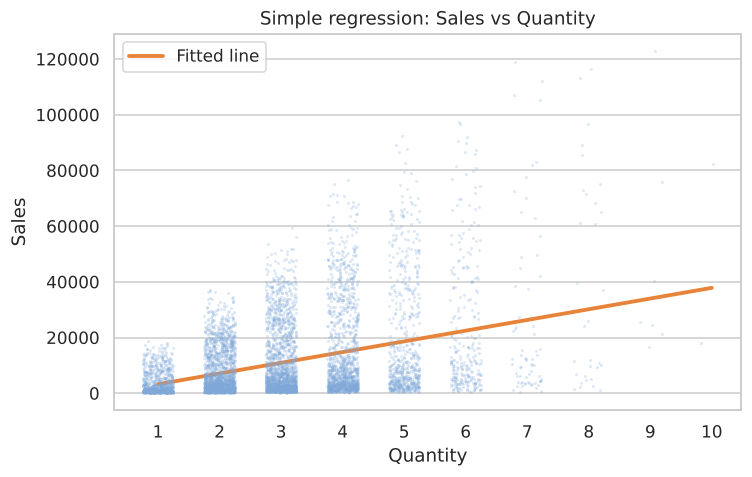

In [10]:
t1, m1, res1 = ols(df[['Quantity']], df.Sales, ['Quantity'])
print(t1.round(4).to_string()); print()
print(f"R-squared = {m1['r2']:.4f} | adjusted R-squared = {m1['adj_r2']:.4f} | F = {m1['F']:,.1f} (p = {m1['F_p']:.3g}) | n = {m1['n']:,} | residual std error = Rs {m1['rmse']:,.0f}")
R['reg1'] = dict(table=t1.round(4).reset_index().to_dict('records'), **{k: float(v) for k, v in m1.items()})

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.stripplot(data=df, x='Quantity', y='Sales', size=2, alpha=.25, color='#7FA8D9', jitter=.25, ax=ax)
xs = np.arange(1, 11); ax.plot(xs - 1, t1.loc['Intercept', 'coef'] + t1.loc['Quantity', 'coef'] * xs, color='#E8833A', lw=2.5, label='Fitted line')
ax.set_title('Simple regression: Sales vs Quantity'); ax.legend(); plt.tight_layout()

### Multiple linear regression: Sales ~ Quantity + Discount + Income
`Sales = b0 + b1 x Quantity + b2 x Discount + b3 x Income`

In [11]:
t2, m2, res2 = ols(df[['Quantity', 'Discount', 'Income']], df.Sales, ['Quantity', 'Discount', 'Income'])
print(t2.round(4).to_string()); print()
print(f"R-squared = {m2['r2']:.4f} | adjusted R-squared = {m2['adj_r2']:.4f} | F = {m2['F']:,.1f} (p = {m2['F_p']:.3g}) | n = {m2['n']:,} | residual std error = Rs {m2['rmse']:,.0f}")
print('\nSignificant predictors (p < 0.05):', [i for i in t2.index[1:] if t2.loc[i, 'p-value'] < ALPHA])
print('Effect of +1 unit Quantity: Rs %.0f | +10 percentage points Discount: Rs %.0f | +Rs 10,000 Income: Rs %.0f' % (t2.loc['Quantity', 'coef'], t2.loc['Discount', 'coef'] * 0.10, t2.loc['Income', 'coef'] * 10000))
R['reg2'] = dict(table=t2.round(6).reset_index().to_dict('records'), **{k: float(v) for k, v in m2.items()})

                 coef   std err       t  p-value      CI low     CI high
Intercept   2,090.322   544.732   3.837    0.000   1,022.482   3,158.162
Quantity    3,843.912   113.391  33.900    0.000   3,621.632   4,066.192
Discount  -15,442.440 1,366.131 -11.304    0.000 -18,120.470 -12,764.409
Income          0.007     0.005   1.375    0.169      -0.003       0.017

R-squared = 0.1546 | adjusted R-squared = 0.1542 | F = 426.3 (p = 2.31e-254) | n = 7,000 | residual std error = Rs 13,380

Significant predictors (p < 0.05): ['Quantity', 'Discount']
Effect of +1 unit Quantity: Rs 3844 | +10 percentage points Discount: Rs -1544 | +Rs 10,000 Income: Rs 71


**Model check.** The fitted line is a rough guide only: the residuals are right-skewed (checked below), because order value depends mainly on the *price of the product*, which this model does not contain. This is why R-squared is low even though Quantity is statistically significant.

In [12]:
print('Residual skewness (multiple model): %.2f' % stats.skew(res2))
print('Correlation of Unit_Price with Sales: %.2f' % df.Unit_Price.corr(df.Sales))
# for context only: adding Unit_Price
t3, m3, _ = ols(df[['Quantity', 'Discount', 'Income', 'Unit_Price']], df.Sales, ['Quantity', 'Discount', 'Income', 'Unit_Price'])
print('R-squared if Unit_Price is also included: %.3f (vs %.3f without)' % (m3['r2'], m2['r2']))
R['reg_context'] = dict(resid_skew=float(stats.skew(res2)), price_corr=float(df.Unit_Price.corr(df.Sales)), r2_with_price=float(m3['r2']))

Residual skewness (multiple model): 1.71
Correlation of Unit_Price with Sales: 0.82
R-squared if Unit_Price is also included: 0.826 (vs 0.155 without)


## 5. Optional Bonus: One-sample z-test on Customer_Rating
**Assumption (stated explicitly):** the company's historical average rating is **3.0** with a known population standard deviation of **1.0**. These are treated as the population parameters.
- **H0:** mean rating = 3.0 | **H1:** mean rating != 3.0 (two-sided)

In [13]:
rt = df.Customer_Rating.dropna(); mu0, sigma0 = 3.0, 1.0
z = (rt.mean() - mu0) / (sigma0 / np.sqrt(len(rt))); pz = 2 * stats.norm.sf(abs(z))
print(f'n rated orders = {len(rt):,} | sample mean = {rt.mean():.4f}')
print(f'z = {z:.4f} | p-value = {pz:.4g}')
print('DECISION:', 'Reject H0' if pz < ALPHA else 'Fail to reject H0', f'at alpha = {ALPHA}')
print('95%% CI for mean rating: %.3f to %.3f' % (rt.mean() - 1.96 * sigma0 / np.sqrt(len(rt)), rt.mean() + 1.96 * sigma0 / np.sqrt(len(rt))))
R['ztest'] = dict(n=len(rt), mean=rt.mean(), z=z, p=pz, reject=bool(pz < ALPHA), lo=rt.mean() - 1.96 / np.sqrt(len(rt)), hi=rt.mean() + 1.96 / np.sqrt(len(rt)))

n rated orders = 6,580 | sample mean = 3.0924
z = 7.4953 | p-value = 6.613e-14
DECISION: Reject H0 at alpha = 0.05
95% CI for mean rating: 3.068 to 3.117


## 6. Summary Table

In [14]:
summary = pd.DataFrame([
    ['t-test (North vs South)', 'Welch t', R['ttest']['t'], R['ttest']['p'], 'Reject H0' if R['ttest']['reject'] else 'Fail to reject H0'],
    ['ANOVA (4 regions)', 'F', R['anova']['F'], R['anova']['p'], 'Reject H0' if R['anova']['reject'] else 'Fail to reject H0'],
    ['Chi-square (Segment x Category)', 'chi2', R['chi2']['chi2'], R['chi2']['p'], 'Reject H0' if R['chi2']['reject'] else 'Fail to reject H0'],
    ['Correlation (Discount, Profit)', 'Pearson r', R['corr']['r'], R['corr']['p'], 'Reject H0' if R['corr']['reject'] else 'Fail to reject H0'],
    ['z-test (Rating vs 3.0)', 'z', R['ztest']['z'], R['ztest']['p'], 'Reject H0' if R['ztest']['reject'] else 'Fail to reject H0']],
    columns=['Test', 'Statistic', 'Value', 'p-value', 'Decision (alpha 0.05)'])
json.dump(R, open('results.json', 'w'), indent=1, default=float)
summary

                              Test  Statistic  Value  p-value Decision (alpha 0.05)
0          t-test (North vs South)    Welch t  0.105    0.916     Fail to reject H0
1                ANOVA (4 regions)          F  0.645    0.586     Fail to reject H0
2  Chi-square (Segment x Category)       chi2  3.453    0.903     Fail to reject H0
3   Correlation (Discount, Profit)  Pearson r -0.121    0.000             Reject H0
4           z-test (Rating vs 3.0)          z  7.495    0.000             Reject H0
